# ❤️ Heart Disease Prediction
### Beginner Machine Learning | Classification

> Can we use basic health measurements to classify whether heart disease is recorded in this dataset?  
> In this project, we use health data to predict the `HeartDisease` label. We explore the dataset, train a Logistic Regression model, and evaluate its predictions. 

**Dataset:** `heart.csv` · **918 records, 12 columns**  
**Problem:** Binary Classification · **Target:** `HeartDisease` (0 = no recorded heart disease, 1 = heart disease)   
**Source:** [Heart Failure Prediction Dataset on Kaggle](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)

## Data Dictionary

> Each row represents a record. The table describes the features and the target.

| Column | Meaning |
|---|---|
| `Age` | Age in years |
| `Sex` | M = male, F = female |
| `ChestPainType` | Type of chest pain (TA, ATA, NAP, ASY) |
| `RestingBP` | Resting blood pressure (mm Hg) |
| `Cholesterol` | Blood cholesterol (mg/dL) |
| `FastingBS` | Fasting blood sugar indicator (0/1) |
| `RestingECG` | Resting ECG category |
| `MaxHR` | Maximum heart rate |
| `ExerciseAngina` | Exercise-related angina (Y/N) |
| `Oldpeak` | ST depression measurement |
| `ST_Slope` | Slope of the ST segment |
| `HeartDisease` | Target: recorded heart disease (0/1) |

## 1. Import Libraries

> We use Pandas to analyze data and Matplotlib and Seaborn to create charts

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load Data

> We load `heart.csv` with Pandas and display the first five rows to get an overview of the dataset

In [2]:
df = pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## 3. Exploratory Data Analysis (EDA)

> We check the dataset size, data types, missing values, and basic statistics

In [3]:
df.shape

(918, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [5]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [6]:
df.describe().round(2)

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.00,918.00,918.00,918.00,918.00,918.00,918.00
mean,53.51,132.40,198.80,0.23,136.81,0.89,0.55
std,9.43,18.51,109.38,0.42,25.46,1.07,0.50
min,28.00,0.00,0.00,0.00,60.00,-2.60,0.00
25%,47.00,120.00,173.25,0.00,120.00,0.00,0.00
50%,54.00,130.00,223.00,0.00,138.00,0.60,1.00
75%,60.00,140.00,267.00,0.00,156.00,1.50,1.00
max,77.00,200.00,603.00,1.00,202.00,6.20,1.00


> Some medical measurements are zero. We check how many values are affected.

In [7]:
(df[['RestingBP', 'Cholesterol']] == 0).sum()

RestingBP        1
Cholesterol    172
dtype: int64

In [21]:
df['HeartDisease'].unique()

array([0, 1])

## 4. Data Visualization

> We compare the target groups and explore maximum heart rate and correlations

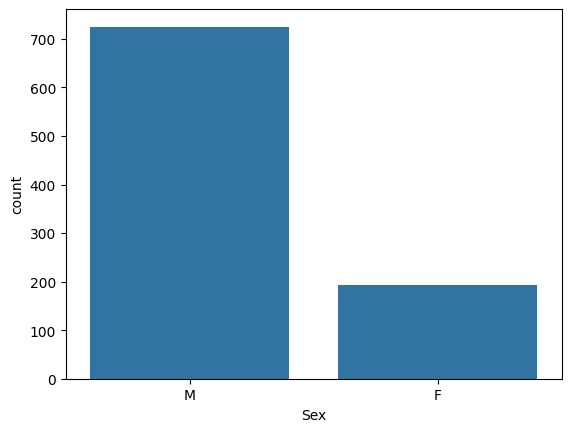

In [20]:
sns.countplot(x=df['Sex']);

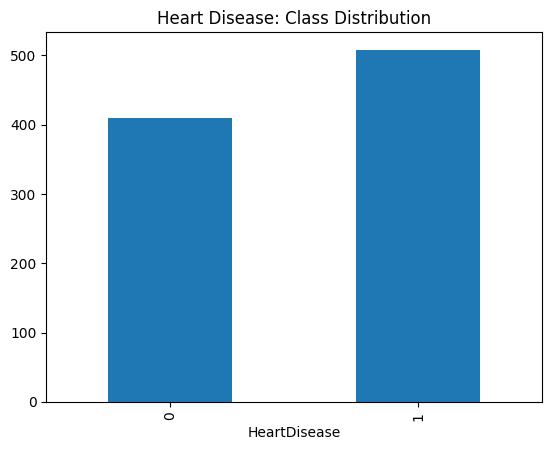

In [11]:
df['HeartDisease'].value_counts().sort_index().plot(kind='bar')
plt.title('Heart Disease: Class Distribution')
plt.show()

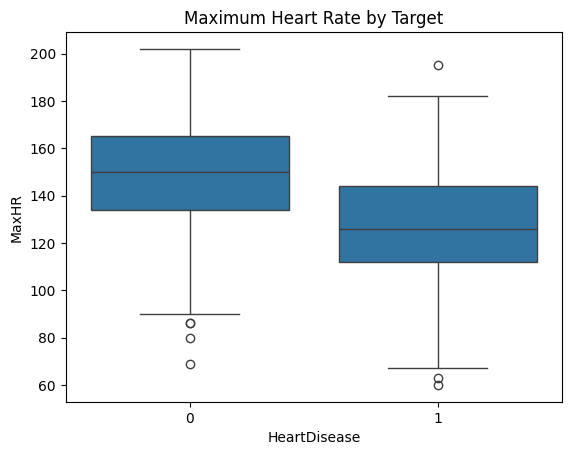

In [12]:
sns.boxplot(data=df, x='HeartDisease', y='MaxHR')
plt.title('Maximum Heart Rate by Target')
plt.show()

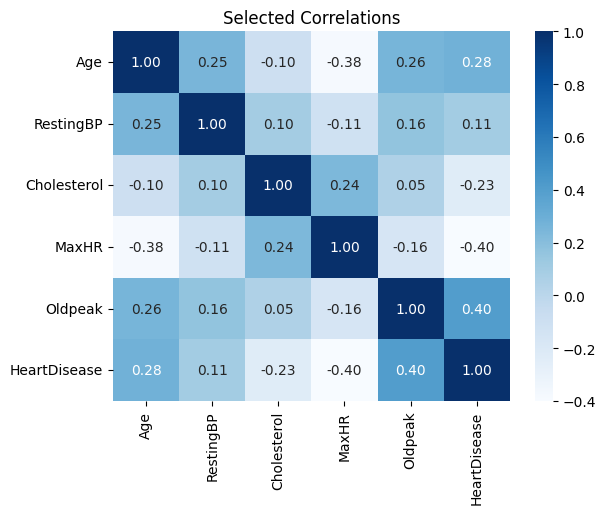

In [13]:
sns.heatmap(df[['Age','RestingBP','Cholesterol','MaxHR','Oldpeak','HeartDisease']].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Selected Correlations')
plt.show()

## 5. Feature Engineering

> `x` contains the input features, and `y` is the target. We convert categories into numeric columns with `get_dummies()`

In [14]:
x = pd.get_dummies(df.drop('HeartDisease', axis=1), drop_first=True)
y = df['HeartDisease']
x.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,True,False,True,False,True,False,False,False,True


## 6. Train and Test

> We use 80% of the data for training and 20% for testing. We fit the scaler only on the training data

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

## 7. Train the Model

> We train Logistic Regression and predict the labels for the test data

In [16]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(x_train, y_train)
y_pred = lr.predict(x_test)

## 8. Evaluation

> We measure Accuracy, Precision, Recall, and F1-Score. The confusion matrix shows correct and incorrect predictions

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print('Accuracy:', round(accuracy_score(y_test, y_pred), 3))
print('Precision:', round(precision_score(y_test, y_pred), 3))
print('Recall:', round(recall_score(y_test, y_pred), 3))
print('F1-Score:', round(f1_score(y_test, y_pred), 3))

Accuracy: 0.886
Precision: 0.872
Recall: 0.931
F1-Score: 0.9


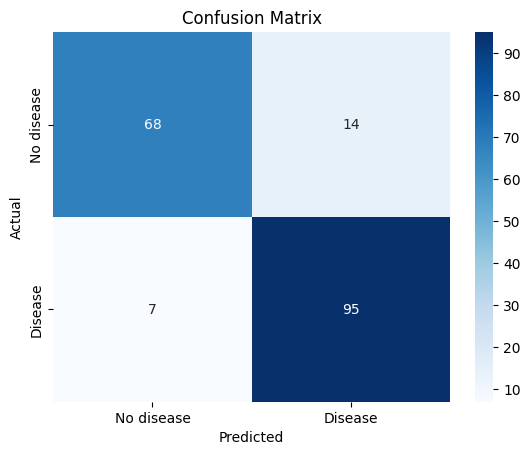

In [18]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No disease', 'Disease'], yticklabels=['No disease', 'Disease'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

> We compare actual labels with model predictions for the first five test records

In [19]:
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
comparison.head()

,Actual,Predicted
356,1,1
763,1,0
817,1,1
735,1,1
892,0,0


## 9. Conclusion

**Test results (80/20 split):** Accuracy **0.886**, Precision **0.872**, Recall **0.931**, F1-Score **0.900**.

> Logistic Regression predicted the recorded heart-disease labels in this dataset. These scores describe one test split, not clinical accuracy.

**Limitations:** `Cholesterol` contains 172 zero values and `RestingBP` contains one. These may indicate unrecorded measurements. The model is for learning and should not be used for medical diagnosis or treatment decisions.